In [5]:
import pandas as pd
from pathlib import Path

df = pd.read_csv('data/resume.csv')

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

Dataset shape: (2484, 4)

Column names:
['ID', 'Resume_str', 'Resume_html', 'Category']

First five rows:


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR



Missing values:
ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ID           2484 non-null   int64
 1   Resume_str   2484 non-null   str  
 2   Resume_html  2484 non-null   str  
 3   Category     2484 non-null   str  
dtypes: int64(1), str(3)
memory usage: 52.3 MB


In [6]:
category_counts = df["Category"].value_counts()

print("Number of job categories:", df["Category"].nunique())
print("\nResumes per category:")
print(category_counts)

Number of job categories: 24

Resumes per category:
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
FINANCE                   118
ENGINEERING               118
ACCOUNTANT                118
FITNESS                   117
AVIATION                  117
SALES                     116
HEALTHCARE                115
CONSULTANT                115
BANKING                   115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


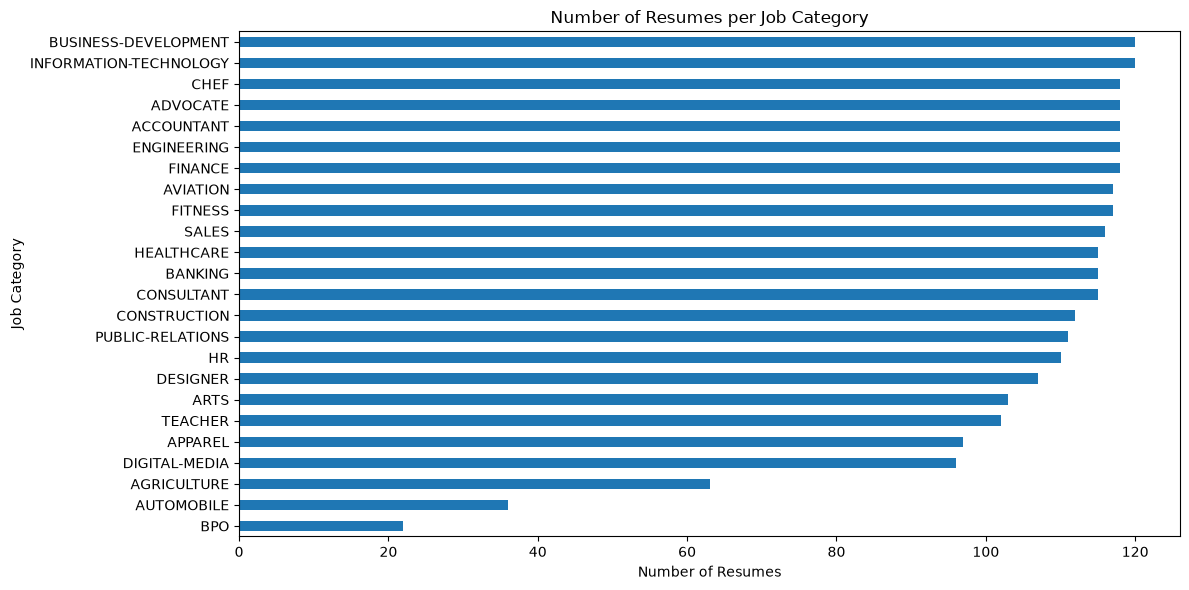

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

category_counts.sort_values().plot(kind="barh")

plt.title("Number of Resumes per Job Category")
plt.xlabel("Number of Resumes")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()

In [8]:
import re

def clean_resume(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Keep letters, numbers, and common technical symbols
    text = re.sub(r"[^a-zA-Z0-9+#./\s-]", " ", text)

    # Normalize repeated whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["cleaned_resume"] = df["Resume_str"].apply(clean_resume)

print("Original resume:")
print(df["Resume_str"].iloc[0][:500])

print("\nCleaned resume:")
print(df["cleaned_resume"].iloc[0][:500])

Original resume:
         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-task

Cleaned resume:
hr administrator/marketing associate hr administrator summary dedicated customer service manager with 15+ years of experience in hospitality and customer service management. respected builder and leader of customer-focused teams strives to instill a shared enthusiastic commitment to customer service. highlights focused on customer satisfaction team management marketing savvy conflict resolution techniques training and development skilled multi-tasker client rel

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Prepare the resume text
resume_texts = df["cleaned_resume"].fillna("")

# Convert resume text into TF-IDF features
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=50000,
    sublinear_tf=True
)

resume_vectors = tfidf.fit_transform(resume_texts)

print("Resume matrix shape:", resume_vectors.shape)

Resume matrix shape: (2484, 50000)


In [10]:
def rank_resumes(job_description, top_n=10):
    # Clean the job description
    cleaned_job = clean_resume(job_description)

    # Convert it using the already-fitted TF-IDF vectorizer
    job_vector = tfidf.transform([cleaned_job])

    # Calculate similarity against every resume
    scores = cosine_similarity(job_vector, resume_vectors).flatten()

    # Get the highest-scoring resumes
    ranked_indices = scores.argsort()[::-1][:top_n]

    results = df.iloc[ranked_indices][["ID", "Category"]].copy()
    results["similarity_score"] = scores[ranked_indices] * 100
    results = results.reset_index(drop=True)
    results.index = results.index + 1
    results.index.name = "Rank"

    return results

In [11]:
job_description = """
Python Developer

Required skills:
Python, Django, REST API, SQL, Git.
Experience in backend development, API development,
database management, debugging, and software development.
"""

ranked_candidates = rank_resumes(job_description, top_n=10)

display(ranked_candidates)

,ID,Category,similarity_score
Rank,,,
1,12144825,AVIATION,13.597817
2,27152464,ENGINEERING,11.529320
3,83816738,INFORMATION-TECHNOLOGY,10.819871
4,62994611,AGRICULTURE,10.649660
5,28762662,ENGINEERING,10.202467
6,11981094,ENGINEERING,9.359469
7,22351830,CONSULTANT,8.674348
8,51588273,ENGINEERING,8.652316
9,29524570,DESIGNER,8.480467


In [12]:
# Skills relevant to technical and software development roles
SKILLS = [
    "python",
    "java",
    "javascript",
    "c++",
    "c#",
    "sql",
    "django",
    "flask",
    "fastapi",
    "rest api",
    "machine learning",
    "deep learning",
    "data analysis",
    "pandas",
    "numpy",
    "scikit-learn",
    "tensorflow",
    "pytorch",
    "html",
    "css",
    "react",
    "node.js",
    "git",
    "docker",
    "aws",
    "linux",
    "mongodb",
    "postgresql",
    "mysql",
    "api development",
    "database management"
]


def extract_skills(text):
    text = str(text).lower()
    found_skills = []

    for skill in SKILLS:
        # Match whole skill phrases rather than partial words
        pattern = r"(?<!\w)" + re.escape(skill) + r"(?!\w)"

        if re.search(pattern, text):
            found_skills.append(skill)

    return found_skills

In [13]:
sample_resume = """
Python developer with experience in Django, REST API,
SQL, Git, Pandas, and database management.
"""

print(extract_skills(sample_resume))

['python', 'sql', 'django', 'rest api', 'pandas', 'git', 'database management']


In [14]:
def match_candidate_skills(job_description, resume_text):
    required_skills = extract_skills(job_description)
    candidate_skills = extract_skills(resume_text)

    matched = sorted(set(required_skills) & set(candidate_skills))
    missing = sorted(set(required_skills) - set(candidate_skills))

    if required_skills:
        skill_match_score = len(matched) / len(set(required_skills)) * 100
    else:
        skill_match_score = 0.0

    return matched, missing, skill_match_score

In [15]:
top_id = int(ranked_candidates.iloc[0]["ID"])

top_resume = df.loc[df["ID"] == top_id, "Resume_str"].iloc[0]

matched, missing, skill_score = match_candidate_skills(
    job_description,
    top_resume
)

print("Candidate ID:", top_id)
print("Matched skills:", matched)
print("Missing skills:", missing)
print(f"Skill match score: {skill_score:.2f}%")

Candidate ID: 12144825
Matched skills: ['git', 'python', 'sql']
Missing skills: ['api development', 'database management', 'django', 'rest api']
Skill match score: 42.86%


In [16]:
def rank_candidates_with_skills(job_description, top_n=10):
    cleaned_job = clean_resume(job_description)
    job_vector = tfidf.transform([cleaned_job])

    # Calculate text similarity for every resume
    similarity_scores = (
        cosine_similarity(job_vector, resume_vectors).flatten() * 100
    )

    # Extract the job's required skills
    required_skills = set(extract_skills(job_description))

    results = []

    for position, (_, row) in enumerate(df.iterrows()):
        resume_text = row["Resume_str"]
        candidate_skills = set(extract_skills(resume_text))

        matched = sorted(required_skills & candidate_skills)
        missing = sorted(required_skills - candidate_skills)

        if required_skills:
            skill_score = len(matched) / len(required_skills) * 100
        else:
            skill_score = 0.0

        text_score = similarity_scores[position]

        # Weighted score
        final_score = 0.60 * text_score + 0.40 * skill_score

        results.append({
            "ID": row["ID"],
            "Category": row["Category"],
            "Text Similarity (%)": round(text_score, 2),
            "Skill Match (%)": round(skill_score, 2),
            "Final Score (%)": round(final_score, 2),
            "Matched Skills": ", ".join(matched) or "None detected",
            "Missing Skills": ", ".join(missing) or "None detected"
        })

    results_df = pd.DataFrame(results)

    return (
        results_df
        .sort_values("Final Score (%)", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
        .rename_axis("Rank")
    )

In [17]:
ranked_candidates = rank_candidates_with_skills(
    job_description,
    top_n=10
)

display(ranked_candidates)

,ID,Category,Text Similarity (%),Skill Match (%),Final Score (%),Matched Skills,Missing Skills
Rank,,,,,,,
0,12144825,AVIATION,13.60,42.86,25.30,"git, python, sql","api development, database management, django, ..."
1,27152464,ENGINEERING,11.53,42.86,24.06,"git, python, sql","api development, database management, django, ..."
2,12011623,ENGINEERING,7.13,42.86,21.42,"database management, python, sql","api development, django, git, rest api"
3,50328713,ENGINEERING,3.81,42.86,19.43,"git, python, sql","api development, database management, django, ..."
4,83816738,INFORMATION-TECHNOLOGY,10.82,28.57,17.92,"git, sql","api development, database management, django, ..."
5,62994611,AGRICULTURE,10.65,28.57,17.82,"python, sql","api development, database management, django, ..."
6,51588273,ENGINEERING,8.65,28.57,16.62,"database management, sql","api development, django, git, python, rest api"
7,29524570,DESIGNER,8.48,28.57,16.52,"database management, sql","api development, django, git, python, rest api"
8,12415691,DESIGNER,8.45,28.57,16.50,"python, sql","api development, database management, django, ..."


In [18]:
top_candidate = ranked_candidates.iloc[0]

print("Top candidate ID:", top_candidate["ID"])
print("Category:", top_candidate["Category"])
print("Text similarity:", top_candidate["Text Similarity (%)"], "%")
print("Skill match:", top_candidate["Skill Match (%)"], "%")
print("Final score:", top_candidate["Final Score (%)"], "%")
print("Matched skills:", top_candidate["Matched Skills"])
print("Missing skills:", top_candidate["Missing Skills"])

Top candidate ID: 12144825
Category: AVIATION
Text similarity: 13.6 %
Skill match: 42.86 %
Final score: 25.3 %
Matched skills: git, python, sql
Missing skills: api development, database management, django, rest api


In [19]:
# Check the categories available in the dataset
print(sorted(df["Category"].unique()))

['ACCOUNTANT', 'ADVOCATE', 'AGRICULTURE', 'APPAREL', 'ARTS', 'AUTOMOBILE', 'AVIATION', 'BANKING', 'BPO', 'BUSINESS-DEVELOPMENT', 'CHEF', 'CONSTRUCTION', 'CONSULTANT', 'DESIGNER', 'DIGITAL-MEDIA', 'ENGINEERING', 'FINANCE', 'FITNESS', 'HEALTHCARE', 'HR', 'INFORMATION-TECHNOLOGY', 'PUBLIC-RELATIONS', 'SALES', 'TEACHER']


In [20]:
def rank_candidates_by_category(
    job_description,
    target_categories,
    top_n=10
):
    # Normalize category names
    target_categories = {
        category.strip().upper()
        for category in target_categories
    }

    # Select resumes from the chosen categories
    filtered_df = df[
        df["Category"].str.upper().isin(target_categories)
    ].copy()

    if filtered_df.empty:
        print("No resumes found for those categories.")
        return pd.DataFrame()

    # Transform the job description
    cleaned_job = clean_resume(job_description)
    job_vector = tfidf.transform([cleaned_job])

    # Score only the filtered resumes
    filtered_vectors = tfidf.transform(
        filtered_df["cleaned_resume"].fillna("")
    )

    similarity_scores = (
        cosine_similarity(job_vector, filtered_vectors).flatten() * 100
    )

    required_skills = set(extract_skills(job_description))
    results = []

    for position, (_, row) in enumerate(filtered_df.iterrows()):
        candidate_skills = set(extract_skills(row["Resume_str"]))

        matched = sorted(required_skills & candidate_skills)
        missing = sorted(required_skills - candidate_skills)

        skill_score = (
            len(matched) / len(required_skills) * 100
            if required_skills else 0.0
        )

        text_score = similarity_scores[position]
        final_score = 0.60 * text_score + 0.40 * skill_score

        results.append({
            "ID": row["ID"],
            "Category": row["Category"],
            "Text Similarity (%)": round(text_score, 2),
            "Skill Match (%)": round(skill_score, 2),
            "Final Score (%)": round(final_score, 2),
            "Matched Skills": ", ".join(matched) or "None detected",
            "Missing Skills": ", ".join(missing) or "None detected"
        })

    return (
        pd.DataFrame(results)
        .sort_values("Final Score (%)", ascending=False)
        .head(top_n)
        .reset_index(drop=True)
        .rename_axis("Rank")
    )

In [21]:
it_candidates = rank_candidates_by_category(
    job_description,
    target_categories=["INFORMATION-TECHNOLOGY"],
    top_n=10
)

display(it_candidates)

,ID,Category,Text Similarity (%),Skill Match (%),Final Score (%),Matched Skills,Missing Skills
Rank,,,,,,,
0,83816738,INFORMATION-TECHNOLOGY,10.82,28.57,17.92,"git, sql","api development, database management, django, ..."
1,20674668,INFORMATION-TECHNOLOGY,6.94,28.57,15.59,"python, sql","api development, database management, django, ..."
2,70089206,INFORMATION-TECHNOLOGY,6.56,28.57,15.36,"database management, sql","api development, django, git, python, rest api"
3,28126340,INFORMATION-TECHNOLOGY,6.06,28.57,15.07,"database management, sql","api development, django, git, python, rest api"
4,13405733,INFORMATION-TECHNOLOGY,5.65,28.57,14.82,"python, sql","api development, database management, django, ..."
5,10265057,INFORMATION-TECHNOLOGY,4.64,28.57,14.21,"python, sql","api development, database management, django, ..."
6,25959103,INFORMATION-TECHNOLOGY,4.17,28.57,13.93,"database management, sql","api development, django, git, python, rest api"
7,18067556,INFORMATION-TECHNOLOGY,3.08,28.57,13.28,"python, sql","api development, database management, django, ..."
8,79541391,INFORMATION-TECHNOLOGY,3.02,28.57,13.24,"database management, sql","api development, django, git, python, rest api"


In [22]:
required_skills = extract_skills(job_description)

print("Job description:")
print(job_description)

print("\nDetected required skills:")
print(required_skills)

print("\nNumber of detected skills:", len(required_skills))

Job description:

Python Developer

Required skills:
Python, Django, REST API, SQL, Git.
Experience in backend development, API development,
database management, debugging, and software development.


Detected required skills:
['python', 'sql', 'django', 'rest api', 'git', 'api development', 'database management']

Number of detected skills: 7


In [23]:
candidate_id = int(it_candidates.iloc[0]["ID"])

candidate_resume = df.loc[
    df["ID"] == candidate_id, "Resume_str"
].iloc[0]

print(candidate_resume[:3000])

         INFORMATION TECHNOLOGY INTERN (TEST AUTOMATION ENGINEER)       Summary      Over 3 years of experience serving as a key contributor across all software development life cycle phases including analysis, architectural design, prototyping, development, and testing of application using Java/J2EE technologies in various domains.  Very good understanding of Object Oriented Programming, Data Structure, Algorithms, Design Patterns and Distributed Systems.  Excellent working experience in backend development using different Spring modules like Spring Core Container Module, AOP, MVC, Security, Data, Transaction Management etc.  Experienced in developing Microservices with Spring Boot, Spring REST, Spring Cloud, etc.  Extensive experience in developing Web interfaces using HTML5, CSS3, Bootstrap, SASS, LESS, JavaScript, jQuery, AngularJS, ReactJS and BackboneJS.  Experienced in working with SQL databases like MySQL, PostgreSQL, Oracle and have some knowledge of NoSQL databases like Mongo

In [24]:
required_skills = extract_skills(job_description)
candidate_skills = extract_skills(candidate_resume)

print("Candidate ID:", candidate_id)
print("\nSkill analysis:")

for skill in required_skills:
    if skill in candidate_skills:
        print(f"✅ Found: {skill}")
    else:
        print(f"❌ Not detected: {skill}")

Candidate ID: 83816738

Skill analysis:
❌ Not detected: python
✅ Found: sql
❌ Not detected: django
❌ Not detected: rest api
✅ Found: git
❌ Not detected: api development
❌ Not detected: database management


In [25]:
import re

SKILL_ALIASES = {
    "python": ["python", "python3", "python 3"],
    "django": ["django"],
    "rest api": [
        "rest api",
        "restful api",
        "restful services",
        "restful web services",
        "django rest framework",
        "djangorestframework"
    ],
    "sql": ["sql", "mysql", "postgresql", "sqlite", "tsql"],
    "git": ["git", "github", "gitlab"],
    "api development": [
        "api development",
        "api development experience",
        "developing apis",
        "developed apis",
        "api integration"
    ],
    "database management": [
        "database management",
        "database administration",
        "database design",
        "database management systems",
        "dbms"
    ]
}


def contains_phrase(text, phrase):
    # Allow flexible whitespace between words
    pattern = r"(?<!\w)" + r"\s+".join(
        re.escape(word) for word in phrase.split()
    ) + r"(?!\w)"

    return bool(re.search(pattern, text, flags=re.IGNORECASE))


def extract_skills(text):
    text = str(text)
    found_skills = []

    for skill, aliases in SKILL_ALIASES.items():
        if any(contains_phrase(text, alias) for alias in aliases):
            found_skills.append(skill)

    return found_skills

In [26]:
candidate_skills = extract_skills(candidate_resume)
required_skills = extract_skills(job_description)

print("Detected candidate skills:", candidate_skills)
print("\nSkill analysis:")

for skill in required_skills:
    status = "Found" if skill in candidate_skills else "Not detected"
    print(f"{skill}: {status}")

Detected candidate skills: ['sql', 'git', 'database management']

Skill analysis:
python: Not detected
django: Not detected
rest api: Not detected
sql: Found
git: Found
api development: Not detected
database management: Found


In [27]:
# Extract skills from every resume
df["extracted_skills"] = df["Resume_str"].apply(extract_skills)

# Count how often each skill appears
skill_counts = (
    df["extracted_skills"]
    .explode()
    .value_counts()
)

print("Skill frequency across resumes:")
display(skill_counts.to_frame("Resume Count"))

Skill frequency across resumes:


,Resume Count
extracted_skills,
sql,191
database management,95
python,40
git,18
rest api,9
api development,2


In [28]:
def rank_candidates_improved(job_description, target_categories, top_n=10):
    categories = {c.strip().upper() for c in target_categories}

    candidates = df[
        df["Category"].str.upper().isin(categories)
    ].copy()

    if candidates.empty:
        return pd.DataFrame()

    required = set(extract_skills(job_description))

    if not required:
        print("No supported skills found in the job description.")
        return pd.DataFrame()

    candidate_skills = candidates["extracted_skills"]

    job_vector = tfidf.transform([clean_resume(job_description)])
    candidate_vectors = tfidf.transform(
        candidates["cleaned_resume"].fillna("")
    )

    similarities = (
        cosine_similarity(job_vector, candidate_vectors).flatten() * 100
    )

    matched_list = []
    missing_list = []
    skill_scores = []

    for found in candidate_skills:
        found = set(found)
        matched = sorted(required & found)
        missing = sorted(required - found)

        matched_list.append(", ".join(matched) or "None detected")
        missing_list.append(", ".join(missing) or "None detected")
        skill_scores.append(100 * len(matched) / len(required))

    results = candidates[["ID", "Category"]].copy()
    results["Text Similarity (%)"] = similarities
    results["Skill Match (%)"] = skill_scores
    results["Final Score (%)"] = (
        0.60 * results["Text Similarity (%)"]
        + 0.40 * results["Skill Match (%)"]
    )
    results["Matched Skills"] = matched_list
    results["Missing Skills"] = missing_list

    results["Screening Result"] = results["Skill Match (%)"].apply(
        screening_recommendation
    )

    results = results.sort_values(
        "Final Score (%)", ascending=False
    ).head(top_n)

    return results.round({
        "Text Similarity (%)": 2,
        "Skill Match (%)": 2,
        "Final Score (%)": 2
    }).reset_index(drop=True)

In [29]:
def screening_recommendation(skill_score):
    if skill_score >= 80:
        return "Strong skill match"
    elif skill_score >= 50:
        return "Moderate skill match"
    else:
        return "Low skill match"

print(screening_recommendation(42.86))

Low skill match


In [30]:
print("screening_recommendation" in globals())

True


In [31]:
improved_ranking = rank_candidates_improved(
    job_description,
    ["INFORMATION-TECHNOLOGY"],
    top_n=10
)

display(improved_ranking)

,ID,Category,Text Similarity (%),Skill Match (%),Final Score (%),Matched Skills,Missing Skills,Screening Result
0,83816738,INFORMATION-TECHNOLOGY,10.82,42.86,23.63,"database management, git, sql","api development, django, python, rest api",Low skill match
1,20674668,INFORMATION-TECHNOLOGY,6.94,28.57,15.59,"python, sql","api development, database management, django, ...",Low skill match
2,70089206,INFORMATION-TECHNOLOGY,6.56,28.57,15.36,"database management, sql","api development, django, git, python, rest api",Low skill match
3,28126340,INFORMATION-TECHNOLOGY,6.06,28.57,15.07,"database management, sql","api development, django, git, python, rest api",Low skill match
4,13385306,INFORMATION-TECHNOLOGY,5.83,28.57,14.93,"database management, sql","api development, django, git, python, rest api",Low skill match
5,13405733,INFORMATION-TECHNOLOGY,5.65,28.57,14.82,"python, sql","api development, database management, django, ...",Low skill match
6,36434348,INFORMATION-TECHNOLOGY,5.22,28.57,14.56,"database management, sql","api development, django, git, python, rest api",Low skill match
7,10265057,INFORMATION-TECHNOLOGY,4.64,28.57,14.21,"python, sql","api development, database management, django, ...",Low skill match
8,16186411,INFORMATION-TECHNOLOGY,4.27,28.57,13.99,"git, sql","api development, database management, django, ...",Low skill match
9,25959103,INFORMATION-TECHNOLOGY,4.17,28.57,13.93,"database management, sql","api development, django, git, python, rest api",Low skill match


In [32]:
def screening_recommendation(skill_score):
    if skill_score >= 80:
        return "Strong skill match"
    elif skill_score >= 50:
        return "Moderate skill match"
    else:
        return "Low skill match"


improved_ranking["Screening Result"] = (
    improved_ranking["Skill Match (%)"]
    .apply(screening_recommendation)
)

display(improved_ranking)

,ID,Category,Text Similarity (%),Skill Match (%),Final Score (%),Matched Skills,Missing Skills,Screening Result
0,83816738,INFORMATION-TECHNOLOGY,10.82,42.86,23.63,"database management, git, sql","api development, django, python, rest api",Low skill match
1,20674668,INFORMATION-TECHNOLOGY,6.94,28.57,15.59,"python, sql","api development, database management, django, ...",Low skill match
2,70089206,INFORMATION-TECHNOLOGY,6.56,28.57,15.36,"database management, sql","api development, django, git, python, rest api",Low skill match
3,28126340,INFORMATION-TECHNOLOGY,6.06,28.57,15.07,"database management, sql","api development, django, git, python, rest api",Low skill match
4,13385306,INFORMATION-TECHNOLOGY,5.83,28.57,14.93,"database management, sql","api development, django, git, python, rest api",Low skill match
5,13405733,INFORMATION-TECHNOLOGY,5.65,28.57,14.82,"python, sql","api development, database management, django, ...",Low skill match
6,36434348,INFORMATION-TECHNOLOGY,5.22,28.57,14.56,"database management, sql","api development, django, git, python, rest api",Low skill match
7,10265057,INFORMATION-TECHNOLOGY,4.64,28.57,14.21,"python, sql","api development, database management, django, ...",Low skill match
8,16186411,INFORMATION-TECHNOLOGY,4.27,28.57,13.99,"git, sql","api development, database management, django, ...",Low skill match
9,25959103,INFORMATION-TECHNOLOGY,4.17,28.57,13.93,"database management, sql","api development, django, git, python, rest api",Low skill match


In [33]:
def screen_candidates():
    print("=== Resume Screening System ===")

    job_description = input(
        "Paste the job description:\n"
    )

    category_input = input(
        "\nEnter category (or ALL): "
    ).strip()

    top_n_input = input(
        "Number of candidates to display (default 10): "
    ).strip()

    top_n = int(top_n_input) if top_n_input else 10

    if category_input.upper() == "ALL":
        categories = df["Category"].dropna().unique().tolist()
    else:
        categories = [category_input.upper()]

    results = rank_candidates_fast(
        job_description,
        categories,
        top_n=top_n
    )

    if results.empty:
        print("No candidates found, or no supported skills were detected.")
    else:
        display(results)

In [34]:
def rank_candidates_fast(job_description, target_categories, top_n=10):
    categories = {c.strip().upper() for c in target_categories}

    candidates = df[
        df["Category"].fillna("").str.upper().isin(categories)
    ].copy()

    if candidates.empty:
        print("No candidates found for this category.")
        return pd.DataFrame()

    # Extract skills once and reuse them for future searches
    if "extracted_skills" not in df.columns:
        print("Preparing candidate skills for the first search...")
        df["extracted_skills"] = (
            df["Resume_str"].fillna("").apply(extract_skills)
        )
        candidates = df[
            df["Category"].fillna("").str.upper().isin(categories)
        ].copy()

    required = set(extract_skills(job_description))

    if not required:
        print("No supported skills detected in the job description.")
        return pd.DataFrame()

    # Reuse the existing TF-IDF vectors instead of recalculating them
    positions = df.index.get_indexer(candidates.index)
    candidate_vectors = resume_vectors[positions]

    job_vector = tfidf.transform([clean_resume(job_description)])
    similarities = (
        cosine_similarity(job_vector, candidate_vectors).flatten() * 100
    )

    matched_skills = []
    missing_skills = []
    skill_scores = []

    for found in candidates["extracted_skills"]:
        matched = sorted(required & set(found))
        missing = sorted(required - set(found))

        matched_skills.append(", ".join(matched) or "None detected")
        missing_skills.append(", ".join(missing) or "None detected")
        skill_scores.append(100 * len(matched) / len(required))

    results = candidates[["ID", "Category"]].copy()
    results["Text Similarity (%)"] = similarities
    results["Skill Match (%)"] = skill_scores
    results["Final Score (%)"] = (
        0.60 * results["Text Similarity (%)"]
        + 0.40 * results["Skill Match (%)"]
    )
    results["Matched Skills"] = matched_skills
    results["Missing Skills"] = missing_skills
    results["Screening Result"] = results["Skill Match (%)"].apply(
        screening_recommendation
    )

    results = results.sort_values(
        "Final Score (%)", ascending=False
    ).head(top_n)

    return results.round({
        "Text Similarity (%)": 2,
        "Skill Match (%)": 2,
        "Final Score (%)": 2
    }).reset_index(drop=True)

In [35]:
improved_ranking = rank_candidates_fast(
    job_description,
    ["INFORMATION-TECHNOLOGY"],
    top_n=10
)

display(improved_ranking)

,ID,Category,Text Similarity (%),Skill Match (%),Final Score (%),Matched Skills,Missing Skills,Screening Result
0,83816738,INFORMATION-TECHNOLOGY,10.82,42.86,23.63,"database management, git, sql","api development, django, python, rest api",Low skill match
1,20674668,INFORMATION-TECHNOLOGY,6.94,28.57,15.59,"python, sql","api development, database management, django, ...",Low skill match
2,70089206,INFORMATION-TECHNOLOGY,6.56,28.57,15.36,"database management, sql","api development, django, git, python, rest api",Low skill match
3,28126340,INFORMATION-TECHNOLOGY,6.06,28.57,15.07,"database management, sql","api development, django, git, python, rest api",Low skill match
4,13385306,INFORMATION-TECHNOLOGY,5.83,28.57,14.93,"database management, sql","api development, django, git, python, rest api",Low skill match
5,13405733,INFORMATION-TECHNOLOGY,5.65,28.57,14.82,"python, sql","api development, database management, django, ...",Low skill match
6,36434348,INFORMATION-TECHNOLOGY,5.22,28.57,14.56,"database management, sql","api development, django, git, python, rest api",Low skill match
7,10265057,INFORMATION-TECHNOLOGY,4.64,28.57,14.21,"python, sql","api development, database management, django, ...",Low skill match
8,16186411,INFORMATION-TECHNOLOGY,4.27,28.57,13.99,"git, sql","api development, database management, django, ...",Low skill match
9,25959103,INFORMATION-TECHNOLOGY,4.17,28.57,13.93,"database management, sql","api development, django, git, python, rest api",Low skill match


In [39]:
import time
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

start = time.time()

# Select IT candidates
mask = df["Category"].fillna("").str.upper().eq(
    "INFORMATION-TECHNOLOGY"
)
candidates = df.loc[mask].copy()

print("IT candidates:", len(candidates))

# Reuse existing TF-IDF vectors
positions = df.index.get_indexer(candidates.index)
candidate_vectors = resume_vectors[positions]

job_vector = tfidf.transform([clean_resume(job_description)])
similarities = cosine_similarity(
    job_vector, candidate_vectors
).flatten() * 100

print("Similarity calculation complete.")

# Calculate skill matches only for the selected candidates
required = set(extract_skills(job_description))
candidate_skills = candidates["Resume_str"].fillna("").apply(extract_skills)

skill_scores = candidate_skills.apply(
    lambda skills: 100 * len(required.intersection(skills)) / len(required)
)

results = candidates[["ID", "Category"]].copy()
results["Text Similarity (%)"] = similarities
results["Skill Match (%)"] = skill_scores.to_numpy()
results["Final Score (%)"] = (
    0.60 * results["Text Similarity (%)"]
    + 0.40 * results["Skill Match (%)"]
)

results = results.sort_values(
    "Final Score (%)", ascending=False
).head(10).reset_index(drop=True)

print("Total time:", round(time.time() - start, 2), "seconds")
display(results)

IT candidates: 120
Similarity calculation complete.
Total time: 0.88 seconds


,ID,Category,Text Similarity (%),Skill Match (%),Final Score (%)
0,83816738,INFORMATION-TECHNOLOGY,10.819871,42.857143,23.634780
1,20674668,INFORMATION-TECHNOLOGY,6.936526,28.571429,15.590487
2,70089206,INFORMATION-TECHNOLOGY,6.559213,28.571429,15.364099
3,28126340,INFORMATION-TECHNOLOGY,6.063733,28.571429,15.066811
4,13385306,INFORMATION-TECHNOLOGY,5.833802,28.571429,14.928853
5,13405733,INFORMATION-TECHNOLOGY,5.648292,28.571429,14.817547
6,36434348,INFORMATION-TECHNOLOGY,5.221163,28.571429,14.561269
7,10265057,INFORMATION-TECHNOLOGY,4.636841,28.571429,14.210676
8,16186411,INFORMATION-TECHNOLOGY,4.268443,28.571429,13.989637
9,25959103,INFORMATION-TECHNOLOGY,4.171781,28.571429,13.931640


In [40]:
def rank_candidates_fast(job_description, target_categories, top_n=10):
    categories = {c.strip().upper() for c in target_categories}

    mask = df["Category"].fillna("").str.upper().isin(categories)
    candidates = df.loc[mask].copy()

    if candidates.empty:
        print("No candidates found.")
        return pd.DataFrame()

    required = set(extract_skills(job_description))

    if not required:
        print("No supported skills detected.")
        return pd.DataFrame()

    # Reuse the existing TF-IDF vectors
    positions = df.index.get_indexer(candidates.index)
    candidate_vectors = resume_vectors[positions]

    job_vector = tfidf.transform([clean_resume(job_description)])
    similarities = (
        cosine_similarity(job_vector, candidate_vectors).flatten() * 100
    )

    # Extract skills only for the selected candidates
    candidate_skills = candidates["Resume_str"].fillna("").apply(extract_skills)

    matched = []
    missing = []
    skill_scores = []

    for skills in candidate_skills:
        found = set(skills)
        matches = sorted(required & found)
        gaps = sorted(required - found)

        matched.append(", ".join(matches) or "None detected")
        missing.append(", ".join(gaps) or "None detected")
        skill_scores.append(100 * len(matches) / len(required))

    results = candidates[["ID", "Category"]].copy()
    results["Text Similarity (%)"] = similarities
    results["Skill Match (%)"] = skill_scores
    results["Final Score (%)"] = (
        0.60 * results["Text Similarity (%)"]
        + 0.40 * results["Skill Match (%)"]
    )
    results["Matched Skills"] = matched
    results["Missing Skills"] = missing
    results["Screening Result"] = results["Skill Match (%)"].apply(
        screening_recommendation
    )

    results = results.sort_values(
        "Final Score (%)", ascending=False
    ).head(top_n)

    return results.round({
        "Text Similarity (%)": 2,
        "Skill Match (%)": 2,
        "Final Score (%)": 2
    }).reset_index(drop=True)

In [41]:
import time

start = time.time()

improved_ranking = rank_candidates_fast(
    job_description,
    ["INFORMATION-TECHNOLOGY"],
    top_n=10
)

print("Time taken:", round(time.time() - start, 2), "seconds")
display(improved_ranking)

Time taken: 0.52 seconds


,ID,Category,Text Similarity (%),Skill Match (%),Final Score (%),Matched Skills,Missing Skills,Screening Result
0,83816738,INFORMATION-TECHNOLOGY,10.82,42.86,23.63,"database management, git, sql","api development, django, python, rest api",Low skill match
1,20674668,INFORMATION-TECHNOLOGY,6.94,28.57,15.59,"python, sql","api development, database management, django, ...",Low skill match
2,70089206,INFORMATION-TECHNOLOGY,6.56,28.57,15.36,"database management, sql","api development, django, git, python, rest api",Low skill match
3,28126340,INFORMATION-TECHNOLOGY,6.06,28.57,15.07,"database management, sql","api development, django, git, python, rest api",Low skill match
4,13385306,INFORMATION-TECHNOLOGY,5.83,28.57,14.93,"database management, sql","api development, django, git, python, rest api",Low skill match
5,13405733,INFORMATION-TECHNOLOGY,5.65,28.57,14.82,"python, sql","api development, database management, django, ...",Low skill match
6,36434348,INFORMATION-TECHNOLOGY,5.22,28.57,14.56,"database management, sql","api development, django, git, python, rest api",Low skill match
7,10265057,INFORMATION-TECHNOLOGY,4.64,28.57,14.21,"python, sql","api development, database management, django, ...",Low skill match
8,16186411,INFORMATION-TECHNOLOGY,4.27,28.57,13.99,"git, sql","api development, database management, django, ...",Low skill match
9,25959103,INFORMATION-TECHNOLOGY,4.17,28.57,13.93,"database management, sql","api development, django, git, python, rest api",Low skill match


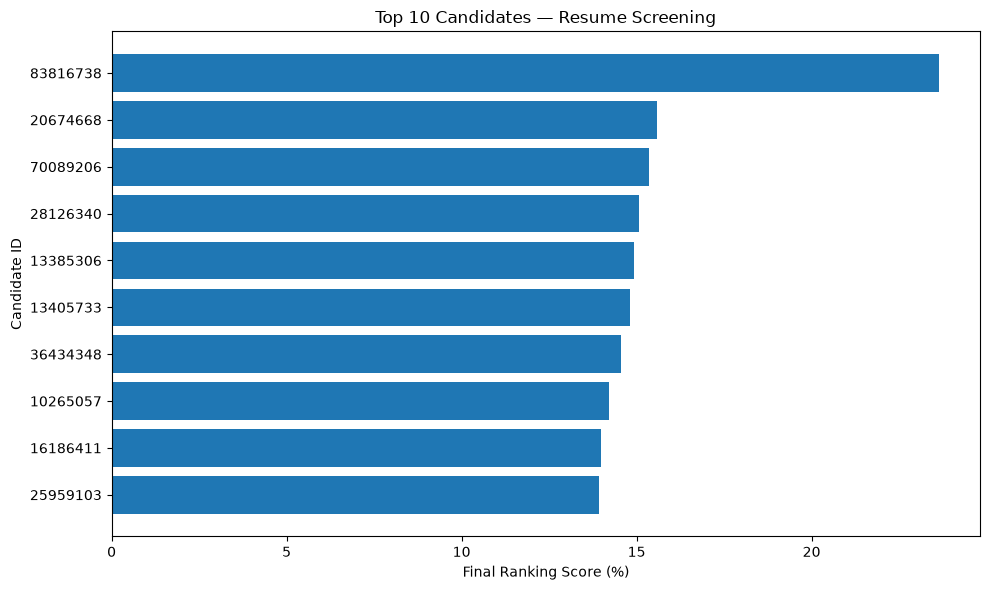

In [42]:
import matplotlib.pyplot as plt

chart_data = improved_ranking.sort_values(
    "Final Score (%)", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    chart_data["ID"].astype(str),
    chart_data["Final Score (%)"]
)

plt.xlabel("Final Ranking Score (%)")
plt.ylabel("Candidate ID")
plt.title("Top 10 Candidates — Resume Screening")
plt.tight_layout()
plt.show()

In [43]:
top_candidate = improved_ranking.iloc[0]

print("Candidate ID:", top_candidate["ID"])
print("Required skills:", sorted(extract_skills(job_description)))
print("Matched skills:", top_candidate["Matched Skills"])
print("Missing skills:", top_candidate["Missing Skills"])
print("Skill match:", top_candidate["Skill Match (%)"], "%")
print("Screening result:", top_candidate["Screening Result"])

Candidate ID: 83816738
Required skills: ['api development', 'database management', 'django', 'git', 'python', 'rest api', 'sql']
Matched skills: database management, git, sql
Missing skills: api development, django, python, rest api
Skill match: 42.86 %
Screening result: Low skill match


## Conclusion

This project implements a Resume / Candidate Screening System using Python, Pandas, and Scikit-learn. It processes resume text, extracts predefined skills, compares resumes with a job description using TF-IDF and cosine similarity, ranks candidates using a combined scoring formula, and identifies detected and missing skills.

### Key Features
- Resume text preprocessing
- TF-IDF-based text similarity
- Keyword-based skill extraction
- Candidate ranking and screening labels
- Matched and missing skills reports
- Candidate ranking visualization

### Limitations
- Skill extraction relies on predefined keywords and aliases.
- The combined ranking score is a heuristic and has not been validated against hiring outcomes.
- Missing skills indicate that a keyword was not detected, not necessarily that the candidate lacks the skill.
- Resume rankings should support human review, not replace it.

### Future Improvements
- Expand skill vocabulary and handle synonyms more accurately.
- Build an interactive interface using Streamlit.
- Evaluate ranking quality on manually reviewed examples.
- Add privacy safeguards and fairness testing.
